# Approach 3: Intent-based Dynamic Query Routing

This notebook implements anchor-based dynamic routing from Section 4.3 of the whitepaper.

Instead of fixed weights, the system **automatically determines per-query weights** by measuring how closely the query aligns with modality-specific "anchors" using the embedding space itself.

**Formula:** `(w_v, w_a, w_t) = softmax(α * sim(E_query, [E_AncV, E_AncA, E_AncT]))` where α=10

In [ ]:
import json
import numpy as np
import boto3
from botocore.config import Config
import matplotlib.pyplot as plt
from collections import defaultdict

# Auto-load configuration from 01_setup_and_embedding.ipynb
with open("config.json") as f:
    config = json.load(f)

REGION = config["REGION"]
S3_BUCKET = config["S3_BUCKET"]
MODEL_ID_SYNC = config["MODEL_ID_SYNC"]
VECTOR_BUCKET = config["VECTOR_BUCKET"]
DATA_S3_PREFIX = config["DATA_S3_PREFIX"]
RESULTS_S3_PREFIX = config["RESULTS_S3_PREFIX"]

print(f"✅ Configuration loaded from config.json")
print(f"   S3 Bucket: {S3_BUCKET}")
print(f"   Vector Bucket: {VECTOR_BUCKET}")

bedrock = boto3.client("bedrock-runtime", region_name=REGION, config=Config(signature_version='v4'))
s3 = boto3.client("s3", region_name=REGION)
s3v = boto3.client("s3vectors", region_name=REGION)

def fmt_time(sec):
    """Convert seconds to mm:ss format"""
    m, s = divmod(sec, 60)
    return f"{int(m):02d}:{s:04.1f}"

def cosine_similarity(a, b):
    a, b = np.array(a), np.array(b)
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

def embed_text(query):
    response = bedrock.invoke_model(
        modelId=MODEL_ID_SYNC,
        body=json.dumps({"inputType": "text", "text": {"inputText": query}})
    )
    return json.loads(response["body"].read())["data"][0]["embedding"]

def softmax(x):
    e_x = np.exp(x - np.max(x))
    return e_x / e_x.sum()

print("Setup complete")

## 1. Load Separate Modality Indices

In [2]:
# Load embeddings from S3
indices = {}
for modality in ["visual", "audio", "transcription"]:
    s3_key = f"{DATA_S3_PREFIX}embeddings_{modality}.json"
    obj = s3.get_object(Bucket=S3_BUCKET, Key=s3_key)
    indices[modality] = json.loads(obj["Body"].read().decode("utf-8"))
    print(f"{modality}: {len(indices[modality])} segments")

visual: 161 segments
audio: 161 segments
transcription: 161 segments


## 2. Define and Embed Routing Anchors

Anchors are text descriptions that represent the semantic intent of each modality.

In [3]:
ANCHORS = {
    "visual": "This document contains content about the visual elements, scenes, objects, and imagery in the video.",
    "audio": "This document contains content about the non-speech audio elements such as music, sound effects, and ambient sounds in the video.",
    "transcription": "This document contains content about the spoken words, dialogue, narration, and speech transcribed from the video."
}

ALPHA = 10

# Embed anchors
anchor_embeddings = {}
for modality, text in ANCHORS.items():
    anchor_embeddings[modality] = embed_text(text)
    print(f"Embedded anchor for {modality}: dim={len(anchor_embeddings[modality])}")

print(f"\nTemperature (alpha): {ALPHA}")
print(f"\nAnchor texts:")
for m, t in ANCHORS.items():
    print(f"  {m}: \"{t}\"")

Embedded anchor for visual: dim=512
Embedded anchor for audio: dim=512
Embedded anchor for transcription: dim=512

Temperature (alpha): 10

Anchor texts:
  visual: "This document contains content about the visual elements, scenes, objects, and imagery in the video."
  audio: "This document contains content about the non-speech audio elements such as music, sound effects, and ambient sounds in the video."
  transcription: "This document contains content about the spoken words, dialogue, narration, and speech transcribed from the video."


## 3. Dynamic Weight Calculation

For each query, compute cosine similarity with each anchor, then apply softmax with temperature α.

In [4]:
def compute_dynamic_weights(query_text, anchor_embeddings, alpha=ALPHA):
    """Compute per-query modality weights using anchor similarity (Equation 4)"""
    q_emb = embed_text(query_text)
    
    similarities = {}
    for modality, anc_emb in anchor_embeddings.items():
        similarities[modality] = cosine_similarity(q_emb, anc_emb)
    
    # Apply softmax with temperature
    sim_array = np.array([similarities["visual"], similarities["audio"], similarities["transcription"]])
    weights_array = softmax(alpha * sim_array)
    
    weights = {
        "visual": float(weights_array[0]),
        "audio": float(weights_array[1]),
        "transcription": float(weights_array[2])
    }
    
    return weights, similarities, q_emb

# Demo with a few queries
demo_queries = [
    "a player scoring a goal with a powerful shot",
    "loud crowd chanting in the stadium",
    "the commentator explains the offside rule",
    "soccer players celebrating after a victory",
    "the announcer discussing match statistics while fans cheer"
]

print("Dynamic Weights Demo:")
print("=" * 80)
for q in demo_queries:
    weights, sims, _ = compute_dynamic_weights(q, anchor_embeddings)
    dominant = max(weights, key=weights.get)
    print(f"\nQuery: \"{q}\"")
    print(f"  Anchor similarities: V={sims['visual']:.4f} A={sims['audio']:.4f} T={sims['transcription']:.4f}")
    print(f"  Dynamic weights:     V={weights['visual']:.4f} A={weights['audio']:.4f} T={weights['transcription']:.4f}")
    print(f"  Dominant modality:   {dominant} ({weights[dominant]*100:.1f}%)")

Dynamic Weights Demo:

Query: "a player scoring a goal with a powerful shot"
  Anchor similarities: V=0.2575 A=0.1102 T=0.2082
  Dynamic weights:     V=0.5433 A=0.1246 T=0.3321
  Dominant modality:   visual (54.3%)

Query: "loud crowd chanting in the stadium"
  Anchor similarities: V=0.1725 A=0.3002 T=0.2152
  Dynamic weights:     V=0.1634 A=0.5862 T=0.2505
  Dominant modality:   audio (58.6%)

Query: "the commentator explains the offside rule"
  Anchor similarities: V=0.3079 A=0.2250 T=0.3528
  Dynamic weights:     V=0.3329 A=0.1454 T=0.5217
  Dominant modality:   transcription (52.2%)

Query: "soccer players celebrating after a victory"
  Anchor similarities: V=0.1680 A=0.0181 T=0.0810
  Dynamic weights:     V=0.6090 A=0.1359 T=0.2551
  Dominant modality:   visual (60.9%)

Query: "the announcer discussing match statistics while fans cheer"
  Anchor similarities: V=0.2425 A=0.2711 T=0.3752
  Dynamic weights:     V=0.1639 A=0.2182 T=0.6179
  Dominant modality:   transcription (61.8%)


## 4. Search with Dynamic Routing

In [5]:
def search_with_dynamic_routing(query_text, anchor_embeddings, alpha=ALPHA, top_k=5):
    """Multi-vector search with dynamically computed weights via S3 Vectors"""
    weights, similarities, q_emb = compute_dynamic_weights(query_text, anchor_embeddings, alpha)
    
    # Search each modality index in S3 Vectors
    combined = defaultdict(lambda: {"scores": {}, "startSec": 0, "endSec": 0})
    
    for modality in weights:
        response = s3v.query_vectors(
            vectorBucketName=VECTOR_BUCKET,
            indexName=modality,
            topK=50,
            queryVector={"float32": [float(x) for x in q_emb]},
            returnMetadata=True,
            returnDistance=True
        )
        for v in response["vectors"]:
            key = (round(v["metadata"]["startSec"], 1), round(v["metadata"]["endSec"], 1))
            combined[key]["scores"][modality] = v["distance"]
            combined[key]["startSec"] = v["metadata"]["startSec"]
            combined[key]["endSec"] = v["metadata"]["endSec"]
    
    # Weighted combination with dynamic weights
    results = []
    for key, data in combined.items():
        score = sum(weights[m] * data["scores"].get(m, 0) for m in weights)
        results.append({
            "startSec": data["startSec"],
            "endSec": data["endSec"],
            "combined_score": score,
            "visual_score": data["scores"].get("visual", 0),
            "audio_score": data["scores"].get("audio", 0),
            "transcription_score": data["scores"].get("transcription", 0)
        })
    
    results.sort(key=lambda x: x["combined_score"], reverse=True)
    return results[:top_k], weights, similarities

## 5. Test: Compare Fixed vs Dynamic Weights

In [6]:
TEST_QUERIES = [
    {"query": "a player kicking the ball towards the goal", "intent": "visual"},
    {"query": "crowd cheering and celebrating loudly", "intent": "audio"},
    {"query": "the commentator describes the player's performance", "intent": "transcription"},
    {"query": "a goal being scored with the stadium erupting", "intent": "visual+audio"},
    {"query": "the announcer explaining a foul while the crowd boos", "intent": "mixed"},
    {"query": "players running on the soccer field", "intent": "visual"},
    {"query": "referee whistle blowing during the match", "intent": "audio"},
    {"query": "the commentator discusses the team's strategy", "intent": "transcription"},
]

FIXED_WEIGHTS = {"visual": 0.8, "audio": 0.1, "transcription": 0.05}

all_dynamic_results = {}
all_weight_data = []

for item in TEST_QUERIES:
    query = item["query"]
    intent = item["intent"]
    
    results, dyn_weights, sims = search_with_dynamic_routing(query, anchor_embeddings)
    all_dynamic_results[query] = results
    all_weight_data.append({
        "query": query,
        "intent": intent,
        "dynamic_weights": dyn_weights,
        "fixed_weights": FIXED_WEIGHTS,
        "anchor_similarities": sims
    })
    
    print(f"\n{'='*70}")
    print(f"Query: \"{query}\" (intent: {intent})")
    print(f"  Fixed weights:   V={FIXED_WEIGHTS['visual']:.2f} A={FIXED_WEIGHTS['audio']:.2f} T={FIXED_WEIGHTS['transcription']:.2f}")
    print(f"  Dynamic weights: V={dyn_weights['visual']:.4f} A={dyn_weights['audio']:.4f} T={dyn_weights['transcription']:.4f}")
    print(f"  Top 3 results:")
    for i, r in enumerate(results[:3], 1):
        print(f"    {i}. [{fmt_time(r['startSec'])}-{fmt_time(r['endSec'])}] score={r['combined_score']:.4f}")


Query: "a player kicking the ball towards the goal" (intent: visual)
  Fixed weights:   V=0.80 A=0.10 T=0.05
  Dynamic weights: V=0.6506 A=0.1534 T=0.1960
  Top 3 results:
    1. [11:28.0-11:35.0] score=0.8704
    2. [05:21.8-05:28.5] score=0.8615
    3. [14:24.2-14:29.8] score=0.8584

Query: "crowd cheering and celebrating loudly" (intent: audio)
  Fixed weights:   V=0.80 A=0.10 T=0.05
  Dynamic weights: V=0.3133 A=0.4335 T=0.2532
  Top 3 results:
    1. [07:40.0-07:45.5] score=0.9014
    2. [01:37.2-01:44.5] score=0.8983
    3. [12:46.2-12:51.2] score=0.8963

Query: "the commentator describes the player's performance" (intent: transcription)
  Fixed weights:   V=0.80 A=0.10 T=0.05
  Dynamic weights: V=0.1431 A=0.1118 T=0.7451
  Top 3 results:
    1. [00:47.5-00:54.5] score=0.6775
    2. [00:40.2-00:47.5] score=0.6697
    3. [00:11.5-00:17.2] score=0.6599

Query: "a goal being scored with the stadium erupting" (intent: visual+audio)
  Fixed weights:   V=0.80 A=0.10 T=0.05
  Dynamic w

## 6. Visualize Dynamic Weight Distributions

Visualization saved to s3://twelvelabs-marengo-test-1755757894/output/marengo-multivector/results/dynamic_weights_comparison.png


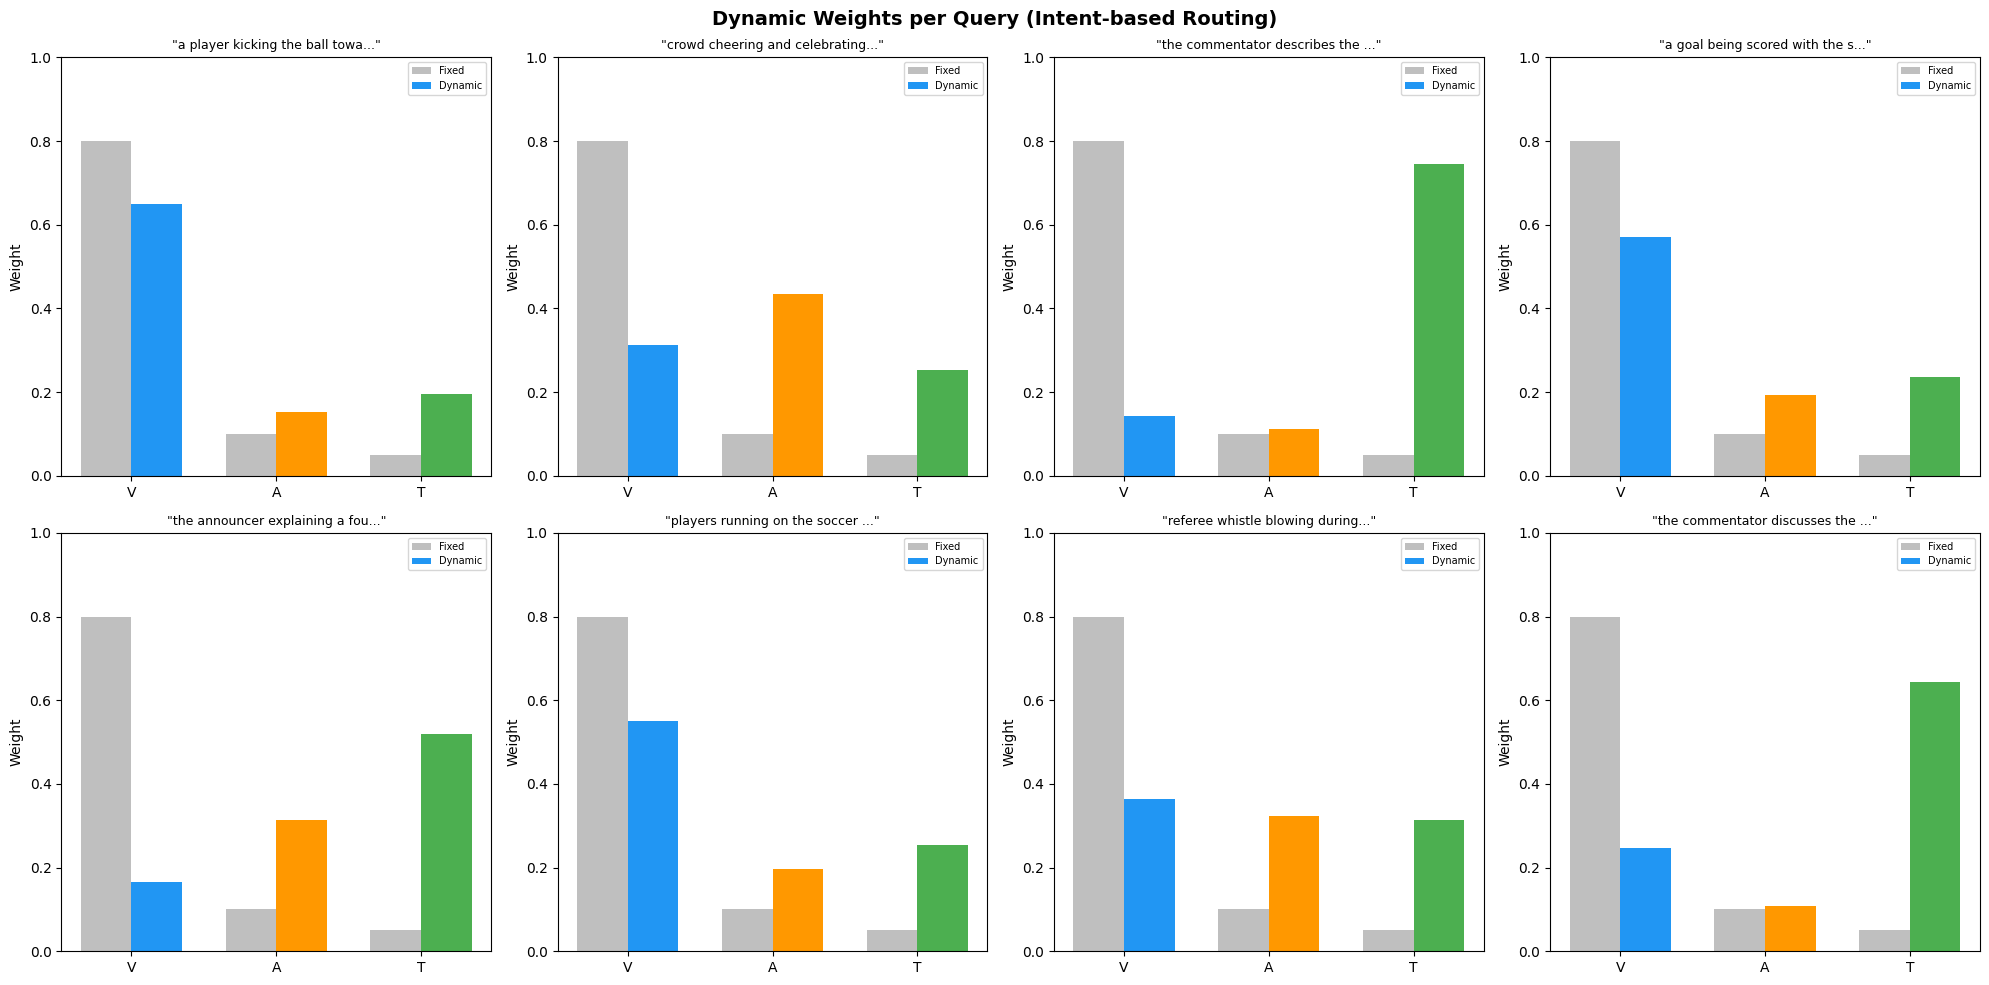

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle("Dynamic Weights per Query (Intent-based Routing)", fontsize=14, fontweight='bold')

colors = {'visual': '#2196F3', 'audio': '#FF9800', 'transcription': '#4CAF50'}

for idx, data in enumerate(all_weight_data):
    row = idx // 4
    col = idx % 4
    ax = axes[row][col]
    
    modalities = list(data["dynamic_weights"].keys())
    dyn_vals = [data["dynamic_weights"][m] for m in modalities]
    fix_vals = [data["fixed_weights"][m] for m in modalities]
    
    x = np.arange(len(modalities))
    width = 0.35
    
    bars1 = ax.bar(x - width/2, fix_vals, width, label='Fixed', alpha=0.5, color='gray')
    bars2 = ax.bar(x + width/2, dyn_vals, width, label='Dynamic', 
                   color=[colors[m] for m in modalities])
    
    ax.set_ylabel('Weight')
    ax.set_title(f'"{ data["query"][:30]}..."' if len(data["query"]) > 30 else f'"{data["query"]}"', fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(['V', 'A', 'T'])
    ax.set_ylim(0, 1.0)
    ax.legend(fontsize=7)

plt.tight_layout()

# Save plot to S3
import io
buf = io.BytesIO()
plt.savefig(buf, format='png', dpi=150, bbox_inches='tight')
buf.seek(0)

s3_key = f"{RESULTS_S3_PREFIX}dynamic_weights_comparison.png"
s3.put_object(
    Bucket=S3_BUCKET,
    Key=s3_key,
    Body=buf.getvalue(),
    ContentType="image/png"
)
print(f"Visualization saved to s3://{S3_BUCKET}/{s3_key}")

plt.show()

## 7. Key Insight: Query-Adaptive Behavior

The intent-based routing system **automatically adjusts weights** based on query semantics:
- Visual queries get high visual weight
- Audio queries get high audio weight
- Transcription queries get high transcription weight
- Mixed queries get balanced weights

This is **deterministic** (same query always gives same weights) and **explainable** (you can inspect anchor similarities).

In [8]:
results_data = {
    "approach": "intent_based_dynamic_routing",
    "alpha": ALPHA,
    "anchors": ANCHORS,
    "weight_data": all_weight_data,
    "results": {q: r for q, r in all_dynamic_results.items()}
}

s3_key = f"{RESULTS_S3_PREFIX}intent_routing_results.json"
s3.put_object(
    Bucket=S3_BUCKET,
    Key=s3_key,
    Body=json.dumps(results_data, indent=2, default=float),
    ContentType="application/json"
)

print(f"Results saved to s3://{S3_BUCKET}/{s3_key}")

Results saved to s3://twelvelabs-marengo-test-1755757894/output/marengo-multivector/results/intent_routing_results.json


---

## 정리: Intent-based Dynamic Routing 접근법

### 구조
```
[사전 준비: 앵커 임베딩 — 서비스 시작 시 1회]
  "visual elements, scenes, objects..."       → embed → anchor_visual (512-dim)
  "non-speech audio, music, sound effects..." → embed → anchor_audio (512-dim)
  "spoken words, dialogue, narration..."      → embed → anchor_trans (512-dim)

[검색 쿼리 처리 — 매 쿼리마다]
  "crowd cheering and celebrating loudly" → embed → query_vector
       │
       ├── 1. 가중치 계산 (cosine + softmax)
       │     cosine(query, anchor_visual) = 0.72
       │     cosine(query, anchor_audio)  = 0.81
       │     cosine(query, anchor_trans)  = 0.68
       │     → softmax(α=10 × [0.72, 0.81, 0.68])
       │     → 가중치: [V=0.24, A=0.60, T=0.16]
       │
       └── 2. 동적 가중치로 검색
             visual 인덱스 검색 → × 0.24
             audio 인덱스 검색  → × 0.60  ← audio가 가장 높은 가중치
             transcription 검색 → × 0.16
             → 합산 → 최종 랭킹
```

### 가중치 자동 계산 원리

**왜 임베딩 공간의 거리로 의도를 파악할 수 있는가?**

Marengo는 텍스트와 영상을 같은 512차원 공간에 놓습니다.
그래서 "crowd cheering"이라는 텍스트는 임베딩 공간에서
audio 관련 앵커 텍스트와 자연스럽게 가까이 위치합니다.

**α(온도 파라미터)의 역할:**

cosine similarity 차이는 보통 미미합니다 (0.72 vs 0.81 vs 0.68).
α를 곱해서 차이를 증폭한 후 softmax를 적용하면 명확한 가중치 분포가 됩니다.

```
α=1:   [0.32, 0.37, 0.31]  → 거의 균등 (차이 증폭 부족)
α=10:  [0.24, 0.60, 0.16]  → 명확한 차이 (권장값)
α=20:  [0.10, 0.82, 0.08]  → 거의 하나만 선택
```
[예시]
Step 1: α 곱하기

  원래 anchor similarity에 α=10을 곱해서 차이를 증폭시킵니다.

  α × 0.2575 = 2.575
  α × 0.1102 = 1.102
  α × 0.2082 = 2.082

  Step 2: 수치 안정성을 위해 max 빼기

  max = 2.575

  2.575 - 2.575 =  0.000
  1.102 - 2.575 = -1.473
  2.082 - 2.575 = -0.493

  Step 3: exp 계산

  exp( 0.000) = 1.0000
  exp(-1.473) = 0.2291
  exp(-0.493) = 0.6107

  Step 4: 합으로 나누기 (정규화)

  sum = 1.0000 + 0.2291 + 0.6107 = 1.8398

  w_v = 1.0000 / 1.8398 = 0.5435  →  54.3%
  w_a = 0.2291 / 1.8398 = 0.1245  →  12.5%
  w_t = 0.6107 / 1.8398 = 0.3320  →  33.2%


### 03번(Fixed Weights) 대비 개선점

| 쿼리 | 03번 Fixed | 04번 Dynamic |
|---|---|---|
| "players running on the soccer field" | V=0.80 A=0.10 T=0.05 | V=**~0.85** A=~0.08 T=~0.07 |
| "crowd cheering and celebrating loudly" | V=0.80 A=0.10 T=0.05 | V=~0.24 A=**~0.60** T=~0.16 |
| "the commentator discusses team's strategy" | V=0.80 A=0.10 T=0.05 | V=~0.09 A=~0.15 T=**~0.76** |

→ 03번은 항상 visual 80%로 고정, 04번은 **쿼리 의도에 따라 자동 조절**

### API 호출 비용

| 항목 | 횟수 | 시점 |
|---|---|---|
| 앵커 임베딩 | 3회 (고정) | 서비스 초기화 시 1번만 |
| 쿼리 임베딩 | 1회/쿼리 | 매 검색 요청 |
| cosine similarity | 3회/쿼리 | 로컬 연산 (거의 무비용) |
| S3 Vectors 검색 | 3회/쿼리 | visual + audio + transcription 각 인덱스 |

→ 03번 대비 추가 비용은 **cosine similarity 3번 + softmax 1번** (무시 가능)

### 이 접근법의 특성
- **자동**: 쿼리마다 가중치를 수동 지정할 필요 없음
- **결정적**: 같은 쿼리는 항상 같은 가중치 (랜덤 요소 없음)
- **설명 가능**: 앵커 유사도를 보면 왜 그 가중치가 나왔는지 추적 가능
- **LLM 불필요**: 쿼리 의도 분류에 LLM 호출이 필요 없음
- **가역적**: 원본 모달리티 임베딩을 보존하므로 앵커 텍스트나 α를 바꿔서 재실험 가능

### 전체 흐름 요약 (02 → 03 → 04)
```
02번 Fused:      저장 시 합침, 가중치 고정, 비가역     → 한계 확인
03번 Fixed:      검색 시 합침, 가중치 고정, 가역적     → 디버깅 가능하나 여전히 고정
04번 Dynamic:    검색 시 합침, 가중치 자동, 가역적     → 쿼리 의도에 적응
```